In [1]:
from pathlib import Path
import json

import numpy as np
import pandas as pd
from google.colab import drive
from IPython.display import display

drive.mount("/content/drive")

folder = Path(
    "/content/drive/MyDrive/EEG_Project/checkpoints/combined_features"
)
df = pd.read_csv(folder / "eeg_features_24_participants_qc_annotated.csv")
schema = json.loads(
    (folder / "eeg_features_24_participants_schema.json").read_text(
        encoding="utf-8"
    )
)

feature_columns = schema["input_feature_columns"]
target_column = "load_level"

primary = df.loc[df["use_in_primary_analysis"].eq(True)].copy()
participants = sorted(primary["participant_id"].unique())

assert len(primary) == 2878
assert len(participants) == 24
assert len(feature_columns) == 57
assert set(primary[target_column]) == {5, 6, 7}
assert not primary.duplicated(["participant_id", "trial_number"]).any()
assert np.isfinite(primary[feature_columns].to_numpy()).all()

seed = 42
shuffled = np.random.default_rng(seed).permutation(participants).tolist()
split_ids = {
    "train": sorted(shuffled[:16]),
    "validation": sorted(shuffled[16:20]),
    "test": sorted(shuffled[20:]),
}

split_by_id = {
    participant: split
    for split, ids in split_ids.items()
    for participant in ids
}
primary["split"] = primary["participant_id"].map(split_by_id)

summary = primary.groupby("split").agg(
    participants=("participant_id", "nunique"),
    trials=("trial_number", "size"),
).reindex(["train", "validation", "test"])

assert summary["participants"].tolist() == [16, 4, 4]
display(summary)

manifest = {
    "seed": seed,
    "target_column": target_column,
    "target_classes": [5, 6, 7],
    "input_feature_columns": feature_columns,
    "participant_splits": split_ids,
    "primary_filter": "use_in_primary_analysis == True",
}
output = folder / "eeg_modeling_split_seed42.json"
output.write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print("Split saved:", output)

Mounted at /content/drive


,participants,trials
split,,
train,16,1919
validation,4,480
test,4,479


Split saved: /content/drive/MyDrive/EEG_Project/checkpoints/combined_features/eeg_modeling_split_seed42.json


In [2]:
from copy import deepcopy

import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score
from sklearn.preprocessing import StandardScaler
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

assert summary["participants"].tolist() == [16, 4, 4]

train = primary.loc[primary["split"].eq("train")]
validation = primary.loc[primary["split"].eq("validation")]

# Fit scaling on training participants only.
scaler = StandardScaler()
X_train = scaler.fit_transform(train[feature_columns]).astype(np.float32)
X_val = scaler.transform(validation[feature_columns]).astype(np.float32)

# Cross-entropy expects class indices 0, 1, 2 for loads 5, 6, 7.
class_ids = {5: 0, 6: 1, 7: 2}
y_train = train[target_column].map(class_ids).to_numpy(dtype=np.int64)
y_val = validation[target_column].map(class_ids).to_numpy(dtype=np.int64)

torch.manual_seed(seed)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

config = {
    "hidden_sizes": [64, 32],
    "dropout": 0.2,
    "learning_rate": 0.001,
    "batch_size": 64,
    "epochs": 30,
}


def build_model(config, n_features):
    hidden_1, hidden_2 = config["hidden_sizes"]
    return nn.Sequential(
        nn.Linear(n_features, hidden_1),
        nn.ReLU(),
        nn.Dropout(config["dropout"]),
        nn.Linear(hidden_1, hidden_2),
        nn.ReLU(),
        nn.Linear(hidden_2, 3),
    )


model = build_model(config, len(feature_columns)).to(device)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=config["learning_rate"])

train_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train)),
    batch_size=config["batch_size"],
    shuffle=True,
    generator=torch.Generator().manual_seed(seed),
)
val_inputs = torch.from_numpy(X_val).to(device)
val_targets = torch.from_numpy(y_val).to(device)

history = []
best_f1 = -1.0

for epoch in range(1, config["epochs"] + 1):
    model.train()
    total_loss = 0.0

    for inputs, targets in train_loader:
        inputs, targets = inputs.to(device), targets.to(device)
        optimizer.zero_grad()
        loss = loss_fn(model(inputs), targets)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(targets)

    model.eval()
    with torch.no_grad():
        logits = model(val_inputs)
        val_loss = loss_fn(logits, val_targets).item()
        predictions = logits.argmax(dim=1).cpu().numpy()

    val_f1 = f1_score(y_val, predictions, average="macro", zero_division=0)
    history.append({
        "epoch": epoch,
        "train_loss": total_loss / len(train),
        "validation_loss": val_loss,
        "validation_accuracy": accuracy_score(y_val, predictions),
        "validation_macro_f1": val_f1,
    })

    if val_f1 > best_f1:
        best_f1 = val_f1
        best_epoch = epoch
        best_state = deepcopy(model.state_dict())

model.load_state_dict(best_state)
history_df = pd.DataFrame(history)

results_dir = folder / "modeling_results"
results_dir.mkdir(exist_ok=True)
history_df.to_csv(results_dir / "centralized_baseline_history.csv", index=False)

torch.save({
    "model_state_dict": {name: weight.cpu() for name, weight in best_state.items()},
    "config": config,
    "feature_columns": feature_columns,
    "class_ids": class_ids,
    "scaler_mean": scaler.mean_.tolist(),
    "scaler_scale": scaler.scale_.tolist(),
    "best_epoch": best_epoch,
    "validation_macro_f1": best_f1,
}, results_dir / "centralized_baseline.pt")

display(history_df.loc[history_df["epoch"].eq(best_epoch)].round(4))
print("Saved baseline and training history to:", results_dir)

,epoch,train_loss,validation_loss,validation_accuracy,validation_macro_f1
9,10,0.9388,1.2733,0.3833,0.3829


Saved baseline and training history to: /content/drive/MyDrive/EEG_Project/checkpoints/combined_features/modeling_results


In [3]:
from copy import deepcopy

from sklearn.metrics import accuracy_score, f1_score
from torch.utils.data import DataLoader, TensorDataset

# Reuse the architecture builder, training-only scaling, and split.
baseline_config = dict(config)
experiments = {
    "baseline": baseline_config,
    "smaller_network": {**baseline_config, "hidden_sizes": [32, 16]},
    "more_dropout": {**baseline_config, "dropout": 0.4},
    "lower_learning_rate": {**baseline_config, "learning_rate": 0.0005},
}


def train_configuration(settings):
    torch.manual_seed(seed)
    candidate = build_model(settings, len(feature_columns)).to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(
        candidate.parameters(), lr=settings["learning_rate"]
    )
    loader = DataLoader(
        TensorDataset(torch.from_numpy(X_train), torch.from_numpy(y_train)),
        batch_size=settings["batch_size"],
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
    )

    records = []
    best_score = -1.0

    for epoch in range(1, settings["epochs"] + 1):
        candidate.train()
        total_loss = 0.0
        for inputs, targets in loader:
            inputs, targets = inputs.to(device), targets.to(device)
            optimizer.zero_grad()
            loss = criterion(candidate(inputs), targets)
            loss.backward()
            optimizer.step()
            total_loss += loss.item() * len(targets)

        candidate.eval()
        with torch.no_grad():
            logits = candidate(val_inputs)
            validation_loss = criterion(logits, val_targets).item()
            predictions = logits.argmax(dim=1).cpu().numpy()

        score = f1_score(y_val, predictions, average="macro", zero_division=0)
        records.append({
            "epoch": epoch,
            "train_loss": total_loss / len(y_train),
            "validation_loss": validation_loss,
            "validation_accuracy": accuracy_score(y_val, predictions),
            "validation_macro_f1": score,
        })
        if score > best_score:
            best_score = score
            weights = deepcopy(candidate.state_dict())

    return pd.DataFrame(records), weights


tuning_rows = []
selected_score = -1.0

for name, settings in experiments.items():
    print(f"Checking configuration: {name}", flush=True)

    if name == "baseline":
        run_history, weights = history_df, best_state
    else:
        run_history, weights = train_configuration(settings)

    row = run_history.loc[run_history["validation_macro_f1"].idxmax()]
    tuning_rows.append({
        "configuration": name,
        "hidden_sizes": str(settings["hidden_sizes"]),
        "dropout": settings["dropout"],
        "learning_rate": settings["learning_rate"],
        "batch_size": settings["batch_size"],
        "best_epoch": int(row["epoch"]),
        "validation_accuracy": float(row["validation_accuracy"]),
        "validation_macro_f1": float(row["validation_macro_f1"]),
    })

    if row["validation_macro_f1"] > selected_score:
        selected_score = float(row["validation_macro_f1"])
        selected_name = name
        selected_epoch = int(row["epoch"])
        selected_config = dict(settings)
        selected_state = {key: value.cpu().clone() for key, value in weights.items()}
        selected_history = run_history.copy()

tuning = pd.DataFrame(tuning_rows).sort_values(
    "validation_macro_f1", ascending=False, kind="stable"
)
tuning.to_csv(results_dir / "centralized_tuning_results.csv", index=False)
selected_history.to_csv(results_dir / "centralized_selected_history.csv", index=False)

torch.save({
    "model_state_dict": selected_state,
    "config": selected_config,
    "feature_columns": feature_columns,
    "class_ids": class_ids,
    "scaler_mean": scaler.mean_.tolist(),
    "scaler_scale": scaler.scale_.tolist(),
    "best_epoch": selected_epoch,
    "validation_macro_f1": selected_score,
}, results_dir / "centralized_selected.pt")

display(tuning.round(4))
print("Selected configuration:", selected_name)
print("Saved to:", results_dir)

Checking configuration: baseline
Checking configuration: smaller_network
Checking configuration: more_dropout
Checking configuration: lower_learning_rate


,configuration,hidden_sizes,dropout,learning_rate,batch_size,best_epoch,validation_accuracy,validation_macro_f1
2,more_dropout,"[64, 32]",0.4,0.0010,64,10,0.4042,0.4010
0,baseline,"[64, 32]",0.2,0.0010,64,10,0.3833,0.3829
3,lower_learning_rate,"[64, 32]",0.2,0.0005,64,11,0.3938,0.3796
1,smaller_network,"[32, 16]",0.2,0.0010,64,12,0.3833,0.3791


Selected configuration: more_dropout
Saved to: /content/drive/MyDrive/EEG_Project/checkpoints/combined_features/modeling_results


In [4]:
from copy import deepcopy

import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

torch.manual_seed(seed)

federated_config = {
    **selected_config,
    "rounds": 30,
    "local_epochs": 1,
}

# Reuse the training-only scaler from the centralized experiment.
# This is a federated simulation within one Colab runtime.
client_loaders = {}
client_sizes = {}

for index, (participant, positions) in enumerate(
    train.groupby("participant_id", sort=True).indices.items()
):
    dataset = TensorDataset(
        torch.from_numpy(X_train[positions]),
        torch.from_numpy(y_train[positions]),
    )
    client_loaders[participant] = DataLoader(
        dataset,
        batch_size=federated_config["batch_size"],
        shuffle=True,
        generator=torch.Generator().manual_seed(seed + index + 1),
    )
    client_sizes[participant] = len(dataset)

assert len(client_loaders) == 16
total_trials = sum(client_sizes.values())
assert total_trials == len(y_train)

# Start from fresh weights so the federated model is trained independently.
global_model = build_model(federated_config, len(feature_columns)).to(device)
criterion = nn.CrossEntropyLoss()
federated_history = []
best_federated_f1 = -1.0

for round_number in range(1, federated_config["rounds"] + 1):
    global_weights = deepcopy(global_model.state_dict())
    averaged_weights = {
        name: torch.zeros_like(weight) for name, weight in global_weights.items()
    }
    total_local_loss = 0.0

    for participant, loader in client_loaders.items():
        client_model = build_model(federated_config, len(feature_columns)).to(device)
        client_model.load_state_dict(global_weights)
        client_model.train()

        optimizer = torch.optim.Adam(
            client_model.parameters(), lr=federated_config["learning_rate"]
        )

        for _ in range(federated_config["local_epochs"]):
            for inputs, targets in loader:
                inputs, targets = inputs.to(device), targets.to(device)
                optimizer.zero_grad()
                loss = criterion(client_model(inputs), targets)
                loss.backward()
                optimizer.step()
                total_local_loss += loss.item() * len(targets)

        share = client_sizes[participant] / total_trials
        for name, weight in client_model.state_dict().items():
            averaged_weights[name].add_(weight, alpha=share)

    global_model.load_state_dict(averaged_weights)
    global_model.eval()
    with torch.no_grad():
        logits = global_model(val_inputs)
        validation_loss = criterion(logits, val_targets).item()
        predictions = logits.argmax(dim=1).cpu().numpy()

    score = f1_score(y_val, predictions, average="macro", zero_division=0)
    federated_history.append({
        "round": round_number,
        "mean_local_training_loss": total_local_loss / (
            total_trials * federated_config["local_epochs"]
        ),
        "validation_loss": validation_loss,
        "validation_accuracy": accuracy_score(y_val, predictions),
        "validation_macro_f1": score,
    })

    if score > best_federated_f1:
        best_federated_f1 = score
        best_round = round_number
        best_federated_state = {
            name: weight.cpu().clone()
            for name, weight in global_model.state_dict().items()
        }

    if round_number % 5 == 0:
        print(f"Round {round_number}: validation macro-F1 = {score:.4f}")

global_model.load_state_dict(best_federated_state)
federated_history_df = pd.DataFrame(federated_history)
federated_history_df.to_csv(results_dir / "federated_history.csv", index=False)

torch.save({
    "model_state_dict": best_federated_state,
    "config": federated_config,
    "feature_columns": feature_columns,
    "class_ids": class_ids,
    "scaler_mean": scaler.mean_.tolist(),
    "scaler_scale": scaler.scale_.tolist(),
    "best_round": best_round,
    "validation_macro_f1": best_federated_f1,
}, results_dir / "federated_selected.pt")

display(
    federated_history_df.loc[federated_history_df["round"].eq(best_round)].round(4)
)
print("Saved federated model and history to:", results_dir)

Round 5: validation macro-F1 = 0.2766
Round 10: validation macro-F1 = 0.2927
Round 15: validation macro-F1 = 0.2595
Round 20: validation macro-F1 = 0.2726
Round 25: validation macro-F1 = 0.2832
Round 30: validation macro-F1 = 0.2916


,round,mean_local_training_loss,validation_loss,validation_accuracy,validation_macro_f1
7,8,1.0971,1.1145,0.3229,0.3014


Saved federated model and history to: /content/drive/MyDrive/EEG_Project/checkpoints/combined_features/modeling_results


In [5]:
import json

import numpy as np
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import accuracy_score, f1_score
from torch import nn

calibration_per_condition = 5
personalization_lr = 0.001
epoch_options = [0, 1, 3, 5, 10]


def calibration_split(subject, trials_per_condition):
    ordered = subject.sort_values("trial_number")
    grouped = ordered.groupby("condition", sort=False)
    if grouped.ngroups != 6 or not grouped.size().gt(trials_per_condition).all():
        raise ValueError("Expected six conditions with calibration and evaluation trials.")

    calibration = grouped.head(trials_per_condition)
    evaluation = ordered.loc[~ordered.index.isin(calibration.index)]
    assert len(calibration) == 6 * trials_per_condition
    return calibration, evaluation


def model_inputs(rows):
    values = scaler.transform(rows[feature_columns]).astype(np.float32)
    return torch.from_numpy(values).to(device)


def model_targets(rows):
    labels = rows[target_column].map(class_ids).to_numpy(dtype=np.int64)
    return torch.from_numpy(labels).to(device)


def personalize(calibration, epochs, learning_rate):
    personalized = build_model(federated_config, len(feature_columns)).to(device)
    personalized.load_state_dict(best_federated_state)

    # Keep the hidden layers fixed and switch off dropout during calibration.
    personalized.eval()
    personalized.requires_grad_(False)
    output_layer = personalized[-1]
    output_layer.requires_grad_(True)

    optimizer = torch.optim.Adam(output_layer.parameters(), lr=learning_rate)
    criterion = nn.CrossEntropyLoss()
    inputs = model_inputs(calibration)
    targets = model_targets(calibration)

    for _ in range(epochs):
        optimizer.zero_grad()
        loss = criterion(personalized(inputs), targets)
        loss.backward()
        optimizer.step()

    return personalized


records = []
for participant, subject in validation.groupby("participant_id"):
    calibration, evaluation = calibration_split(subject, calibration_per_condition)
    inputs = model_inputs(evaluation)
    targets = model_targets(evaluation).cpu().numpy()

    for epochs in epoch_options:
        personalized = personalize(calibration, epochs, personalization_lr)
        with torch.no_grad():
            predictions = personalized(inputs).argmax(dim=1).cpu().numpy()

        records.append({
            "participant_id": participant,
            "adaptation_epochs": epochs,
            "calibration_trials": len(calibration),
            "evaluation_trials": len(evaluation),
            "accuracy": accuracy_score(targets, predictions),
            "macro_f1": f1_score(
                targets, predictions, labels=[0, 1, 2],
                average="macro", zero_division=0,
            ),
        })

personalization_details = pd.DataFrame(records)
personalization_summary = (
    personalization_details.groupby("adaptation_epochs")
    .agg(
        mean_participant_accuracy=("accuracy", "mean"),
        mean_participant_macro_f1=("macro_f1", "mean"),
    )
    .reset_index()
)

# Select an adaptation setting, with 0 epochs kept as the FedAvg reference.
selected_personalization = (
    personalization_summary.loc[personalization_summary["adaptation_epochs"].gt(0)]
    .sort_values(
        ["mean_participant_macro_f1", "adaptation_epochs"],
        ascending=[False, True],
    )
    .iloc[0]
)
personalization_epochs = int(selected_personalization["adaptation_epochs"])

personalization_details.to_csv(
    results_dir / "personalization_validation_by_participant.csv", index=False
)
personalization_summary.to_csv(
    results_dir / "personalization_validation_summary.csv", index=False
)
(results_dir / "personalization_config.json").write_text(
    json.dumps({
        "calibration_trials_per_condition": calibration_per_condition,
        "learning_rate": personalization_lr,
        "adaptation_epochs": personalization_epochs,
        "trainable_layer": "output",
    }, indent=2),
    encoding="utf-8",
)

display(personalization_summary.round(4))
print("Selected adaptation epochs:", personalization_epochs)

,adaptation_epochs,mean_participant_accuracy,mean_participant_macro_f1
0,0,0.3194,0.2518
1,1,0.3139,0.2540
2,3,0.3222,0.2682
3,5,0.3333,0.2819
4,10,0.3444,0.2986


Selected adaptation epochs: 10


In [6]:
import pandas as pd
import torch
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    roc_auc_score,
)

test = primary.loc[primary["split"].eq("test")].copy()
assert test["participant_id"].nunique() == 4
assert set(test["participant_id"]).isdisjoint(
    set(train["participant_id"]) | set(validation["participant_id"])
)

central_test_model = build_model(selected_config, len(feature_columns)).to(device)
central_test_model.load_state_dict(selected_state)
central_test_model.eval()

fed_test_model = build_model(federated_config, len(feature_columns)).to(device)
fed_test_model.load_state_dict(best_federated_state)
fed_test_model.eval()

prediction_tables = []
calibration_tables = []

for participant, subject in test.groupby("participant_id", sort=True):
    calibration, evaluation = calibration_split(subject, calibration_per_condition)
    assert set(calibration.index).isdisjoint(evaluation.index)

    calibration_tables.append(
        calibration[["participant_id", "trial_number", "condition", "load_level"]]
    )

    personalized_model = personalize(
        calibration, personalization_epochs, personalization_lr
    )
    inputs = model_inputs(evaluation)

    models = {
        "Centralized ANN": central_test_model,
        "FedAvg ANN": fed_test_model,
        "Personalized FedAvg ANN": personalized_model,
    }

    for name, evaluated_model in models.items():
        evaluated_model.eval()
        with torch.no_grad():
            probabilities = evaluated_model(inputs).softmax(dim=1).cpu().numpy()

        result = evaluation[
            ["participant_id", "trial_number", "task_type", "load_level"]
        ].copy()
        result["model"] = name
        result["predicted_load"] = probabilities.argmax(axis=1) + 5
        result[["prob_load_5", "prob_load_6", "prob_load_7"]] = probabilities
        prediction_tables.append(result)

predictions = pd.concat(prediction_tables, ignore_index=True)
calibration_trials = pd.concat(calibration_tables, ignore_index=True)

keys = ["participant_id", "trial_number"]
assert len(calibration_trials) == 120
assert not predictions.duplicated(["model", *keys]).any()

evaluation_keys = test[keys].merge(calibration_trials[keys], on=keys, how="left",
                                   indicator=True)
evaluation_keys = evaluation_keys.loc[evaluation_keys["_merge"].eq("left_only")]
expected_keys = set(evaluation_keys[keys].itertuples(index=False, name=None))

metrics = []
for name, rows in predictions.groupby("model", sort=False):
    assert set(rows[keys].itertuples(index=False, name=None)) == expected_keys

    actual = rows["load_level"]
    predicted = rows["predicted_load"]
    precision, recall, f1, _ = precision_recall_fscore_support(
        actual, predicted, labels=[5, 6, 7], average="macro", zero_division=0
    )

    metrics.append({
        "model": name,
        "test_trials": len(rows),
        "accuracy": accuracy_score(actual, predicted),
        "macro_precision": precision,
        "macro_recall": recall,
        "macro_f1": f1,
        "macro_roc_auc_ovr": roc_auc_score(
            actual,
            rows[["prob_load_5", "prob_load_6", "prob_load_7"]].to_numpy(),
            labels=[5, 6, 7],
            multi_class="ovr",
            average="macro",
        ),
    })

test_metrics = pd.DataFrame(metrics)
test_metrics.to_csv(results_dir / "final_test_metrics.csv", index=False)
predictions.to_csv(results_dir / "final_test_predictions.csv", index=False)
calibration_trials.to_csv(results_dir / "test_calibration_trials.csv", index=False)

display(test_metrics.round(4))
print("Saved final test metrics and predictions to:", results_dir)

,model,test_trials,accuracy,macro_precision,macro_recall,macro_f1,macro_roc_auc_ovr
0,Centralized ANN,359,0.3036,0.3098,0.3035,0.3036,0.4752
1,FedAvg ANN,359,0.3538,0.3573,0.3543,0.3276,0.4750
2,Personalized FedAvg ANN,359,0.3538,0.3643,0.3541,0.3397,0.4797


Saved final test metrics and predictions to: /content/drive/MyDrive/EEG_Project/checkpoints/combined_features/modeling_results


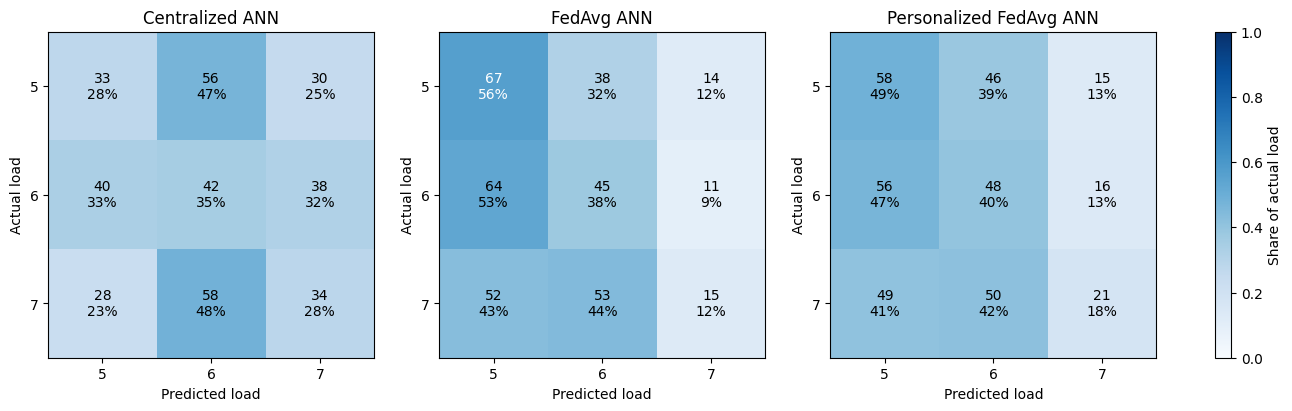

Per-class recall — diagonal of the confusion matrices:


model,Centralized ANN,FedAvg ANN,Personalized FedAvg ANN
load,,,
5,0.277,0.563,0.487
6,0.350,0.375,0.400
7,0.283,0.125,0.175


Macro-F1 by participant_id:


model,Centralized ANN,FedAvg ANN,Personalized FedAvg ANN
group,,,
sub-002,0.350,0.340,0.371
sub-009,0.242,0.303,0.317
sub-014,0.209,0.243,0.281
sub-022,0.241,0.270,0.290


Macro-F1 by task_type:


model,Centralized ANN,FedAvg ANN,Personalized FedAvg ANN
group,,,
M,0.273,0.316,0.292
R,0.325,0.330,0.383


Saved error analysis to: /content/drive/MyDrive/EEG_Project/checkpoints/combined_features/modeling_results


In [7]:
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    precision_recall_fscore_support,
)

predictions = pd.read_csv(results_dir / "final_test_predictions.csv")
loads = [5, 6, 7]

class_records = []
group_records = []

fig, axes = plt.subplots(1, 3, figsize=(13, 4), constrained_layout=True)

for ax, (model_name, rows) in zip(
    axes, predictions.groupby("model", sort=False)
):
    actual = rows["load_level"]
    predicted = rows["predicted_load"]

    precision, recall, f1, support = precision_recall_fscore_support(
        actual, predicted, labels=loads, zero_division=0
    )
    for load, p, r, score, count in zip(loads, precision, recall, f1, support):
        class_records.append({
            "model": model_name,
            "load": load,
            "precision": p,
            "recall": r,
            "f1": score,
            "trials": count,
        })

    matrix = confusion_matrix(actual, predicted, labels=loads)
    proportions = matrix / matrix.sum(axis=1, keepdims=True)
    heatmap = ax.imshow(proportions, cmap="Blues", vmin=0, vmax=1)

    for i in range(len(loads)):
        for j in range(len(loads)):
            value = proportions[i, j]
            ax.text(
                j, i, f"{matrix[i, j]}\n{value:.0%}",
                ha="center", va="center",
                color="white" if value > 0.55 else "black",
            )

    ax.set_title(model_name)
    ax.set_xticks(range(len(loads)), loads)
    ax.set_yticks(range(len(loads)), loads)
    ax.set_xlabel("Predicted load")
    ax.set_ylabel("Actual load")

    for group_column in ["participant_id", "task_type"]:
        for group, subset in rows.groupby(group_column):
            _, _, score, _ = precision_recall_fscore_support(
                subset["load_level"], subset["predicted_load"],
                labels=loads, average="macro", zero_division=0,
            )
            group_records.append({
                "model": model_name,
                "group_type": group_column,
                "group": group,
                "trials": len(subset),
                "accuracy": accuracy_score(
                    subset["load_level"], subset["predicted_load"]
                ),
                "macro_f1": score,
            })

fig.colorbar(heatmap, ax=axes, label="Share of actual load")
fig.savefig(results_dir / "test_confusion_matrices.png", dpi=200)
plt.show()
plt.close(fig)

per_class = pd.DataFrame(class_records)
by_group = pd.DataFrame(group_records)

per_class.to_csv(results_dir / "test_per_class_metrics.csv", index=False)
by_group.to_csv(results_dir / "test_group_metrics.csv", index=False)

print("Per-class recall — diagonal of the confusion matrices:")
display(per_class.pivot(index="load", columns="model", values="recall").round(3))

for group_column in ["participant_id", "task_type"]:
    print(f"Macro-F1 by {group_column}:")
    display(
        by_group.loc[by_group["group_type"].eq(group_column)]
        .pivot(index="group", columns="model", values="macro_f1")
        .round(3)
    )

print("Saved error analysis to:", results_dir)

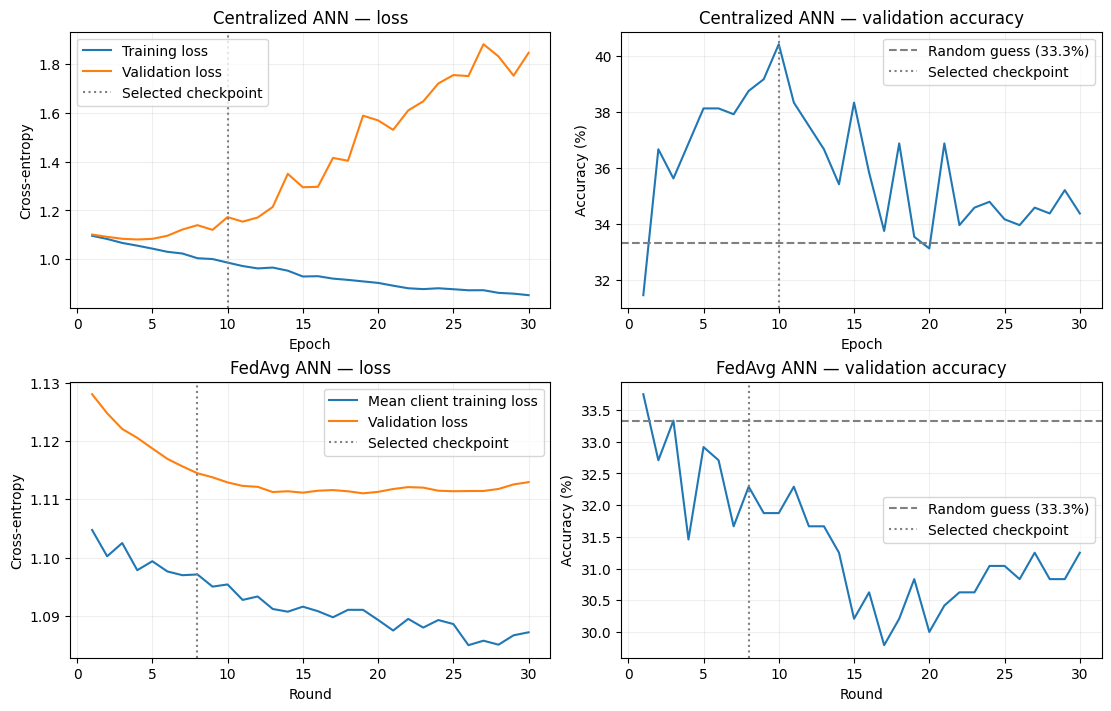

Saved: /content/drive/MyDrive/EEG_Project/checkpoints/combined_features/modeling_results/training_and_validation_curves.png


In [8]:
import matplotlib.pyplot as plt
import pandas as pd

central = pd.read_csv(results_dir / "centralized_selected_history.csv")
federated = pd.read_csv(results_dir / "federated_history.csv")

fig, axes = plt.subplots(2, 2, figsize=(11, 7), constrained_layout=True)

runs = [
    ("Centralized ANN", central, "epoch", "train_loss", "Training loss"),
    ("FedAvg ANN", federated, "round", "mean_local_training_loss", "Mean client training loss"),
]

for row, (name, history, step, train_loss, train_label) in enumerate(runs):
    selected_step = history.loc[history["validation_macro_f1"].idxmax(), step]
    loss_ax, accuracy_ax = axes[row]

    loss_ax.plot(history[step], history[train_loss], label=train_label)
    loss_ax.plot(history[step], history["validation_loss"], label="Validation loss")
    loss_ax.set(title=f"{name} — loss", xlabel=step.capitalize(), ylabel="Cross-entropy")
    loss_ax.axvline(selected_step, color="gray", linestyle=":", label="Selected checkpoint")
    loss_ax.legend()

    accuracy_ax.plot(history[step], 100 * history["validation_accuracy"])
    accuracy_ax.axhline(100 / 3, color="gray", linestyle="--", label="Random guess (33.3%)")
    accuracy_ax.axvline(selected_step, color="gray", linestyle=":", label="Selected checkpoint")
    accuracy_ax.set(
        title=f"{name} — validation accuracy",
        xlabel=step.capitalize(),
        ylabel="Accuracy (%)",
    )
    accuracy_ax.legend()

for ax in axes.flat:
    ax.grid(alpha=0.2)

output = results_dir / "training_and_validation_curves.png"
fig.savefig(output, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print("Saved:", output)

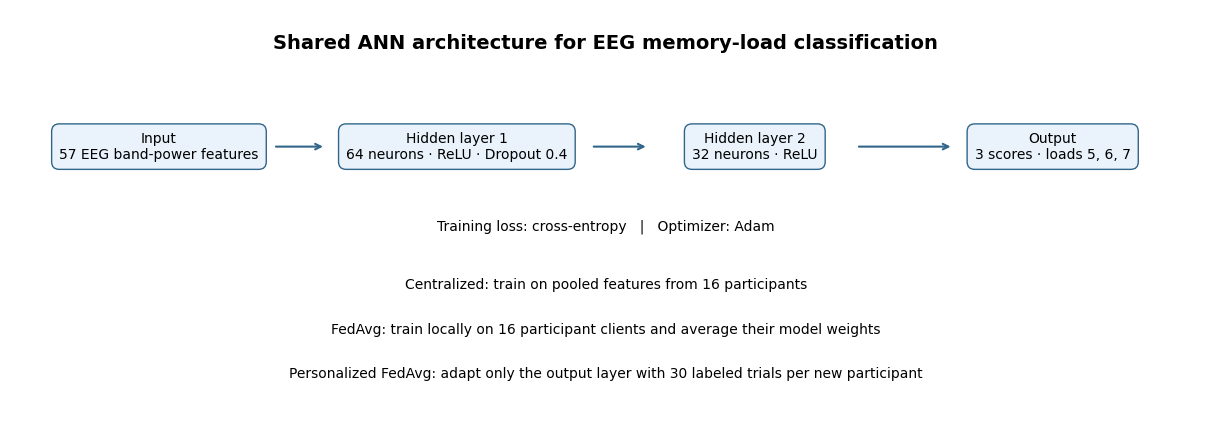

Saved: /content/drive/MyDrive/EEG_Project/checkpoints/combined_features/modeling_results/eeg_ann_architecture.png


In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 4.3), constrained_layout=True)
ax.set(xlim=(0, 12), ylim=(0, 4.3))
ax.axis("off")

blocks = [
    (1.5, "Input\n57 EEG band-power features"),
    (4.5, "Hidden layer 1\n64 neurons · ReLU · Dropout 0.4"),
    (7.5, "Hidden layer 2\n32 neurons · ReLU"),
    (10.5, "Output\n3 scores · loads 5, 6, 7"),
]

for x, label in blocks:
    ax.text(
        x, 2.9, label, ha="center", va="center", fontsize=10,
        bbox=dict(boxstyle="round,pad=0.55", fc="#eaf3fb", ec="#31668a"),
    )

for left, right in [(2.65, 3.18), (5.85, 6.43), (8.52, 9.5)]:
    ax.annotate(
        "", xy=(right, 2.9), xytext=(left, 2.9),
        arrowprops=dict(arrowstyle="->", color="#31668a", lw=1.5),
    )

ax.text(6, 3.9, "Shared ANN architecture for EEG memory-load classification",
        ha="center", fontsize=14, fontweight="bold")
ax.text(6, 2.05, "Training loss: cross-entropy   |   Optimizer: Adam",
        ha="center", fontsize=10)
ax.text(6, 1.45, "Centralized: train on pooled features from 16 participants",
        ha="center", fontsize=10)
ax.text(6, 1.0, "FedAvg: train locally on 16 participant clients and average their model weights",
        ha="center", fontsize=10)
ax.text(6, 0.55, "Personalized FedAvg: adapt only the output layer with 30 labeled trials per new participant",
        ha="center", fontsize=10)

output = results_dir / "eeg_ann_architecture.png"
fig.savefig(output, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)
print("Saved:", output)

In [10]:
from pathlib import Path
from shutil import copy2, which
import subprocess

from google.colab import files

repo = Path("/content/eeg-deliverable2-report-repo")
repo_url = "https://github.com/EmanAdil122/federated-eeg-working-memory.git"

if not repo.exists():
    subprocess.run(
        ["git", "clone", "--depth", "1", repo_url, str(repo)],
        check=True,
    )

paper = repo / "paper"
figure_dir = paper / "figures" / "modeling"
figure_dir.mkdir(parents=True, exist_ok=True)

results_dir = Path(
    "/content/drive/MyDrive/EEG_Project/checkpoints/"
    "combined_features/modeling_results"
)

for name in [
    "eeg_ann_architecture.png",
    "training_and_validation_curves.png",
    "test_confusion_matrices.png",
]:
    copy2(results_dir / name, figure_dir / name)

uploaded = files.upload()
if len(uploaded) != 1:
    raise ValueError("Select only deliverable2_report.tex.")

filename, contents = next(iter(uploaded.items()))
if not filename.endswith(".tex"):
    raise ValueError("Select the downloaded .tex file.")

tex = paper / "deliverable2_report.tex"
tex.write_bytes(contents)

if which("pdflatex") is None:
    subprocess.run(["apt-get", "update", "-qq"], check=True)
    subprocess.run(
        ["apt-get", "install", "-y", "-qq",
         "texlive-latex-extra", "texlive-fonts-recommended"],
        check=True,
    )

for _ in range(2):
    result = subprocess.run(
        ["pdflatex", "-interaction=nonstopmode", "-halt-on-error", tex.name],
        cwd=paper,
        capture_output=True,
        text=True,
    )
    if result.returncode != 0:
        print("\n".join(result.stdout.splitlines()[-25:]))
        raise RuntimeError("PDF compile nahi hui. Upar LaTeX error dekho.")

pdf = paper / "deliverable2_report.pdf"
print("PDF ready:", pdf)
files.download(str(pdf))

Saving deliverable2_report.tex to deliverable2_report.tex
PDF ready: /content/eeg-deliverable2-report-repo/paper/deliverable2_report.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [11]:
from pathlib import Path
from zipfile import ZipFile
from google.colab import files

repo = Path("/content/eeg-deliverable2-report-repo")
report_files = [
    "paper/deliverable2_report.tex",
    "paper/deliverable2_report.pdf",
    "paper/figures/modeling/eeg_ann_architecture.png",
    "paper/figures/modeling/training_and_validation_curves.png",
    "paper/figures/modeling/test_confusion_matrices.png",
]

zip_path = Path("/content/deliverable2_report_files.zip")
with ZipFile(zip_path, "w") as archive:
    for name in report_files:
        archive.write(repo / name, arcname=name)

files.download(str(zip_path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>